# Urban Water Consumption Forecasting and Smart Resource Allocation
DAV Complex Engineering Problem · executable analysis and saved outputs

Run **Runtime → Run all** in Google Colab. The setup downloads the public repository and installs the pinned dependencies. Outputs below were generated by executing every analysis cell in a local Jupyter kernel, not in a hosted Colab session. The same notebook is configured for Colab.

The study uses 156 monthly Austin retail billing observations from 2012–2024 and ERA5 weather. Training is 2012–2022, validation is 2023 and the untouched test is 2024. The 2025 forecast is a historical experiment from December 2024. Supply and capacity limits are demonstration assumptions. Large volume is an industrial proxy; municipal billing is a priority-area proxy.

In [1]:
from pathlib import Path
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules or Path("/content").exists()
if IN_COLAB:
    project = Path("/content/urban-water-consumption-forecasting")
    if not project.exists():
        subprocess.run(["git", "clone", "https://github.com/ajshnadar26/urban-water-consumption-forecasting.git", str(project)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(project / "requirements.txt")], check=True)
    os.chdir(project)
else:
    project = Path.cwd()
    if not (project / "src/pipeline.py").exists() and (project.parent / "src/pipeline.py").exists():
        project = project.parent
    os.chdir(project)
assert (project / "src/pipeline.py").exists(), "Run from the project root or notebooks folder."
sys.path.insert(0, str(project))
print("Project ready. Python", sys.version.split()[0])

Project ready. Python 3.12.14


## 1 Data collection and preprocessing
Raw CSV/JSON snapshots and attribution are included in the repository. Exact duplicates are removed; conflicting keys and malformed values are rejected. Valid unusual months and billing adjustments are retained. Missing months are filled only from prior data; leading gaps fail validation.

In [2]:
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image
from src.pipeline import load_data, run
from src.allocation import allocate, SECTORS
frame, audit = load_data()
print(json.dumps(audit, indent=2))
display(frame.head().round(2))

{
  "residential": {
    "raw_rows": 26819,
    "exact_duplicates_removed": 0,
    "negative_adjustment_rows": 0
  },
  "commercial": {
    "raw_rows": 35065,
    "exact_duplicates_removed": 0,
    "negative_adjustment_rows": 2
  },
  "missing_sector_months_ffilled": 0,
  "excluded_classes_gallons_all_source_dates": {
    "Austin Water Utility": 628229800.0,
    "Wholesale": 37437983200.0
  },
  "analysis_rows": 156,
  "start": "2012-01-01",
  "end": "2024-12-01",
  "industrial_caveat": "Large volume is a billing-class proxy; the source does not identify industrial end-use.",
  "scope": "Selected retail classes; wholesale and utility use excluded to avoid possible double counting."
}


,Residential,Commercial,Large volume,Municipal,total_mg,temperature_2m_mean,precipitation_sum,days_in_month,weekend_days,month,year,rolling_mean_12,rolling_variance_12
date,,,,,,,,,,,,,
2012-01-01,1729.63,652.81,225.38,31.31,2639.13,12.68,125.9,31,9,1,2012,NaN,NaN
2012-02-01,1512.36,614.48,251.13,34.26,2412.23,13.76,110.4,29,8,2,2012,NaN,NaN
2012-03-01,1648.38,668.12,251.01,46.20,2613.72,19.04,159.0,31,9,3,2012,NaN,NaN
2012-04-01,1767.03,687.64,261.27,45.45,2761.39,22.92,16.5,30,9,4,2012,NaN,NaN
2012-05-01,2212.72,822.45,274.76,55.87,3365.80,25.53,119.2,31,8,5,2012,NaN,NaN


## 2 Reproduce the full analysis
This executes the repository implementation rather than reading precomputed metrics. Source code for fitting, diagnostics and evaluation is in `src/pipeline.py`; constrained optimization is in `src/allocation.py`. The next cells inspect the outputs generated by this run.

In [3]:
from contextlib import redirect_stdout
import io
analysis_log = io.StringIO()
with redirect_stdout(analysis_log):
    run()
summary = json.loads(Path("results/summary.json").read_text())
print("Analysis completed from raw snapshots.")
print("Selected model:", summary["selected_model"])
print("ARIMA order:", summary["arima_order"])
print("Flagged months:", summary["flagged_months"])

Analysis completed from raw snapshots.
Selected model: Holt Winters
ARIMA order: [2, 1, 2]
Flagged months: 4


## 3 Exploration and stationarity
Rolling mean and variance describe changing moments. ADF is applied to training data only. Differencing and ACF/PACF inform the ARIMA candidates, which are ranked by converged training AIC.

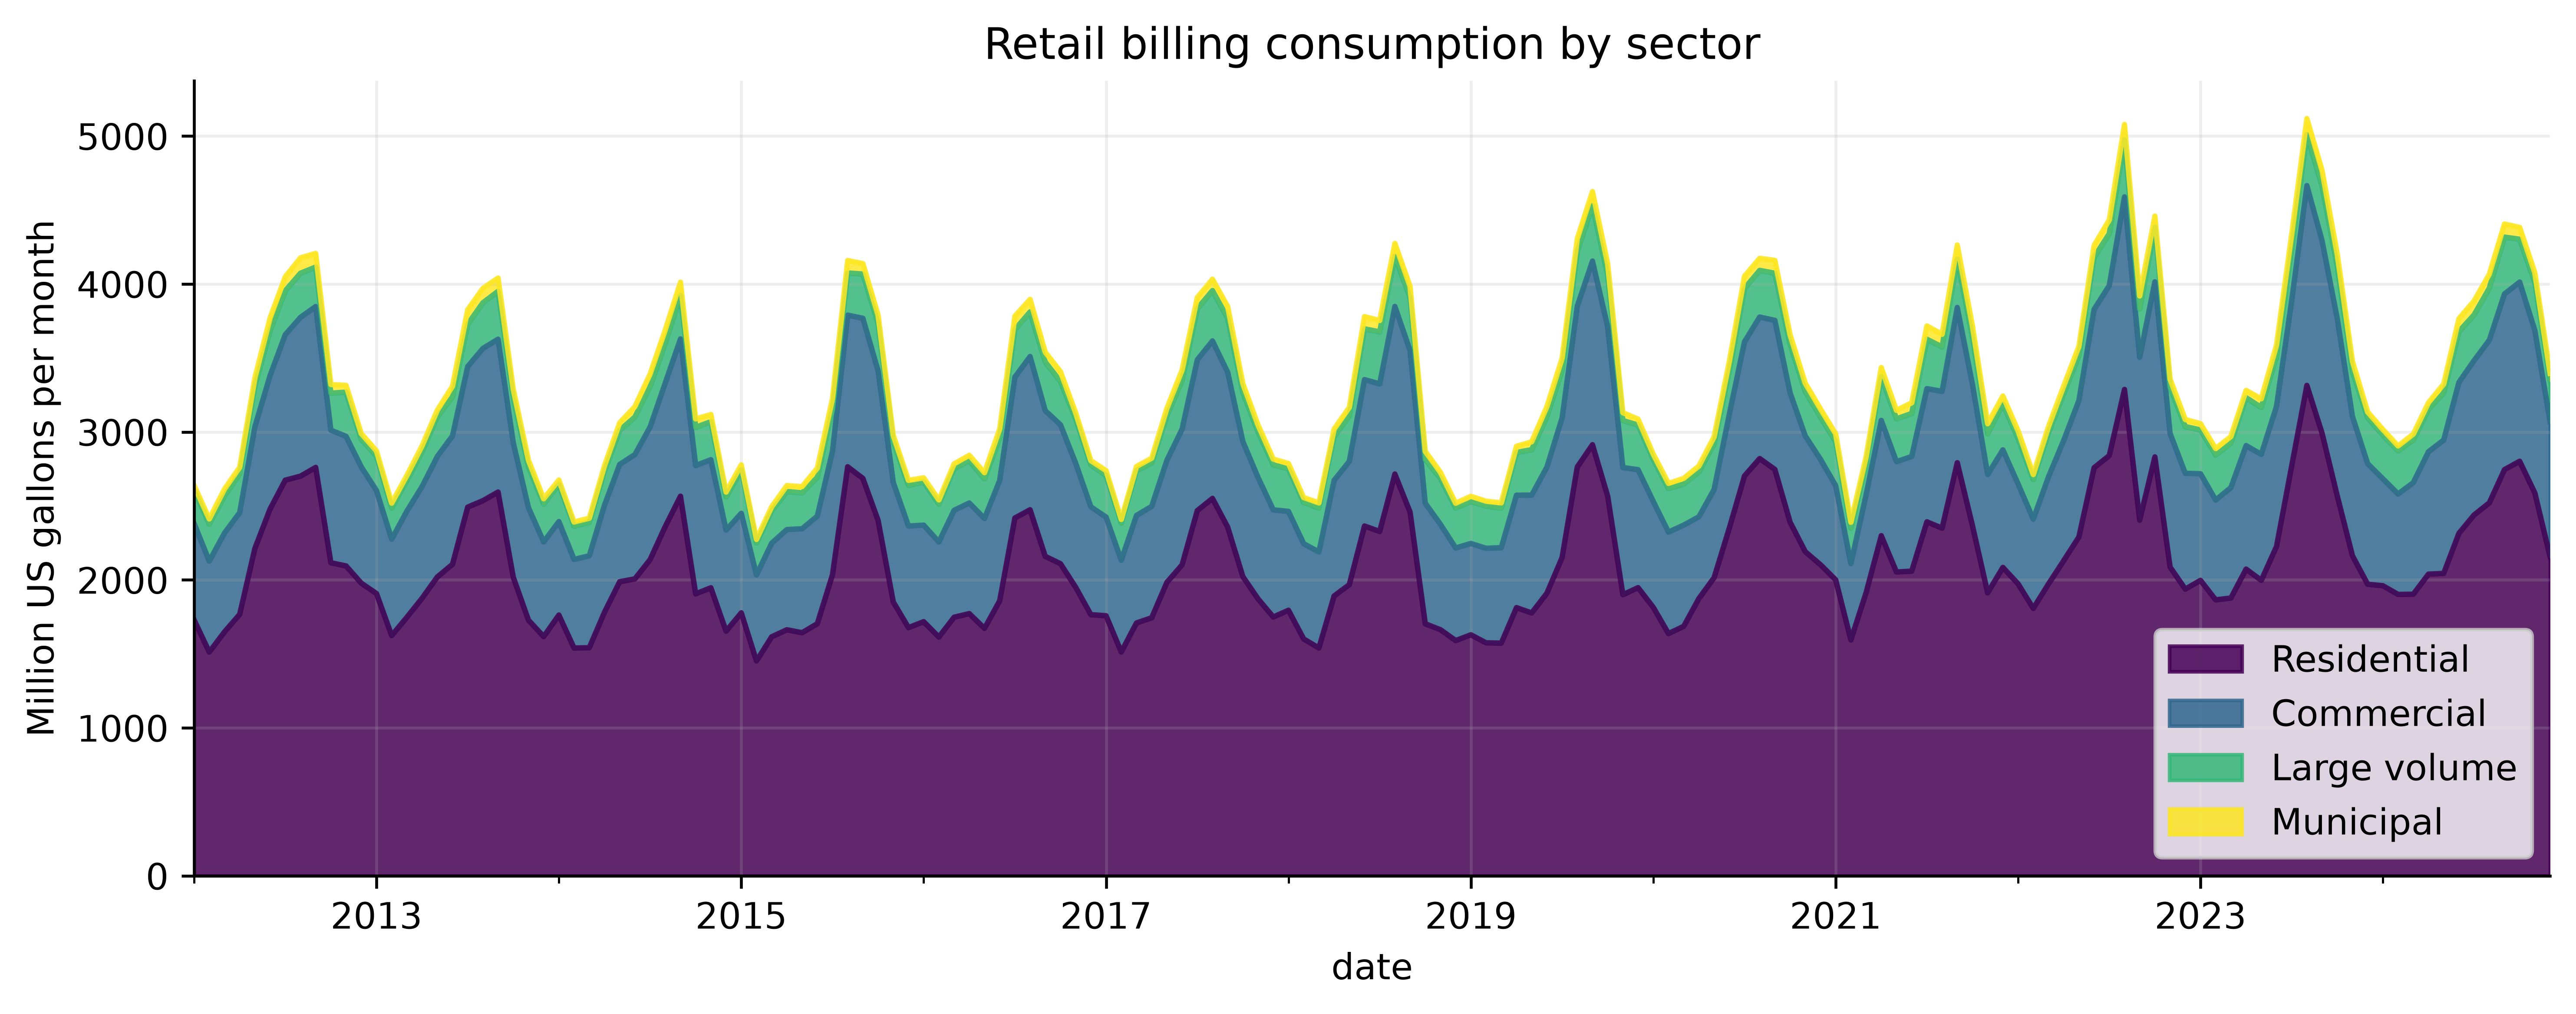

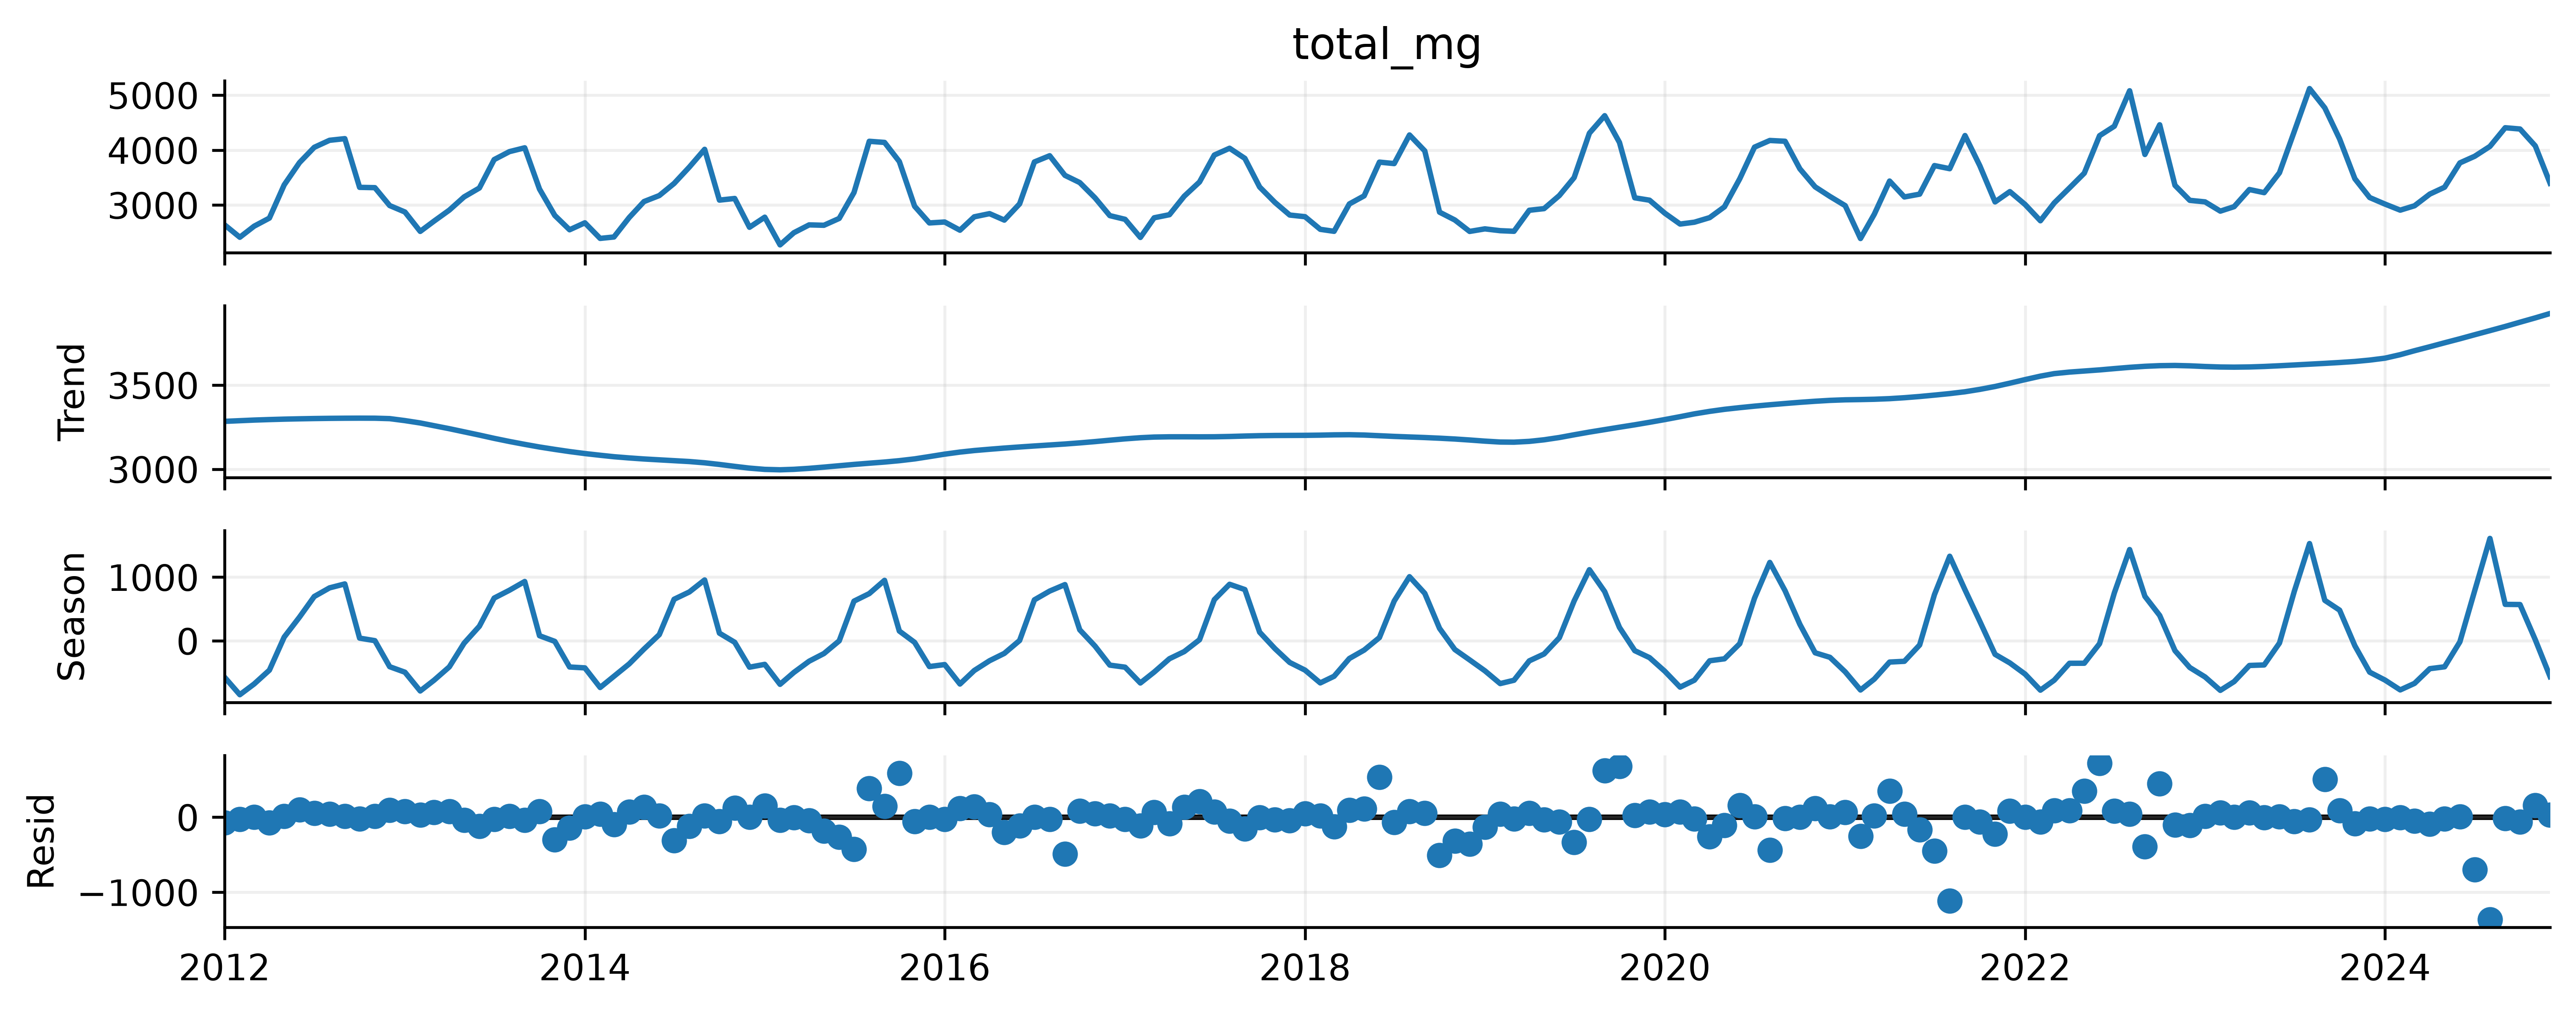

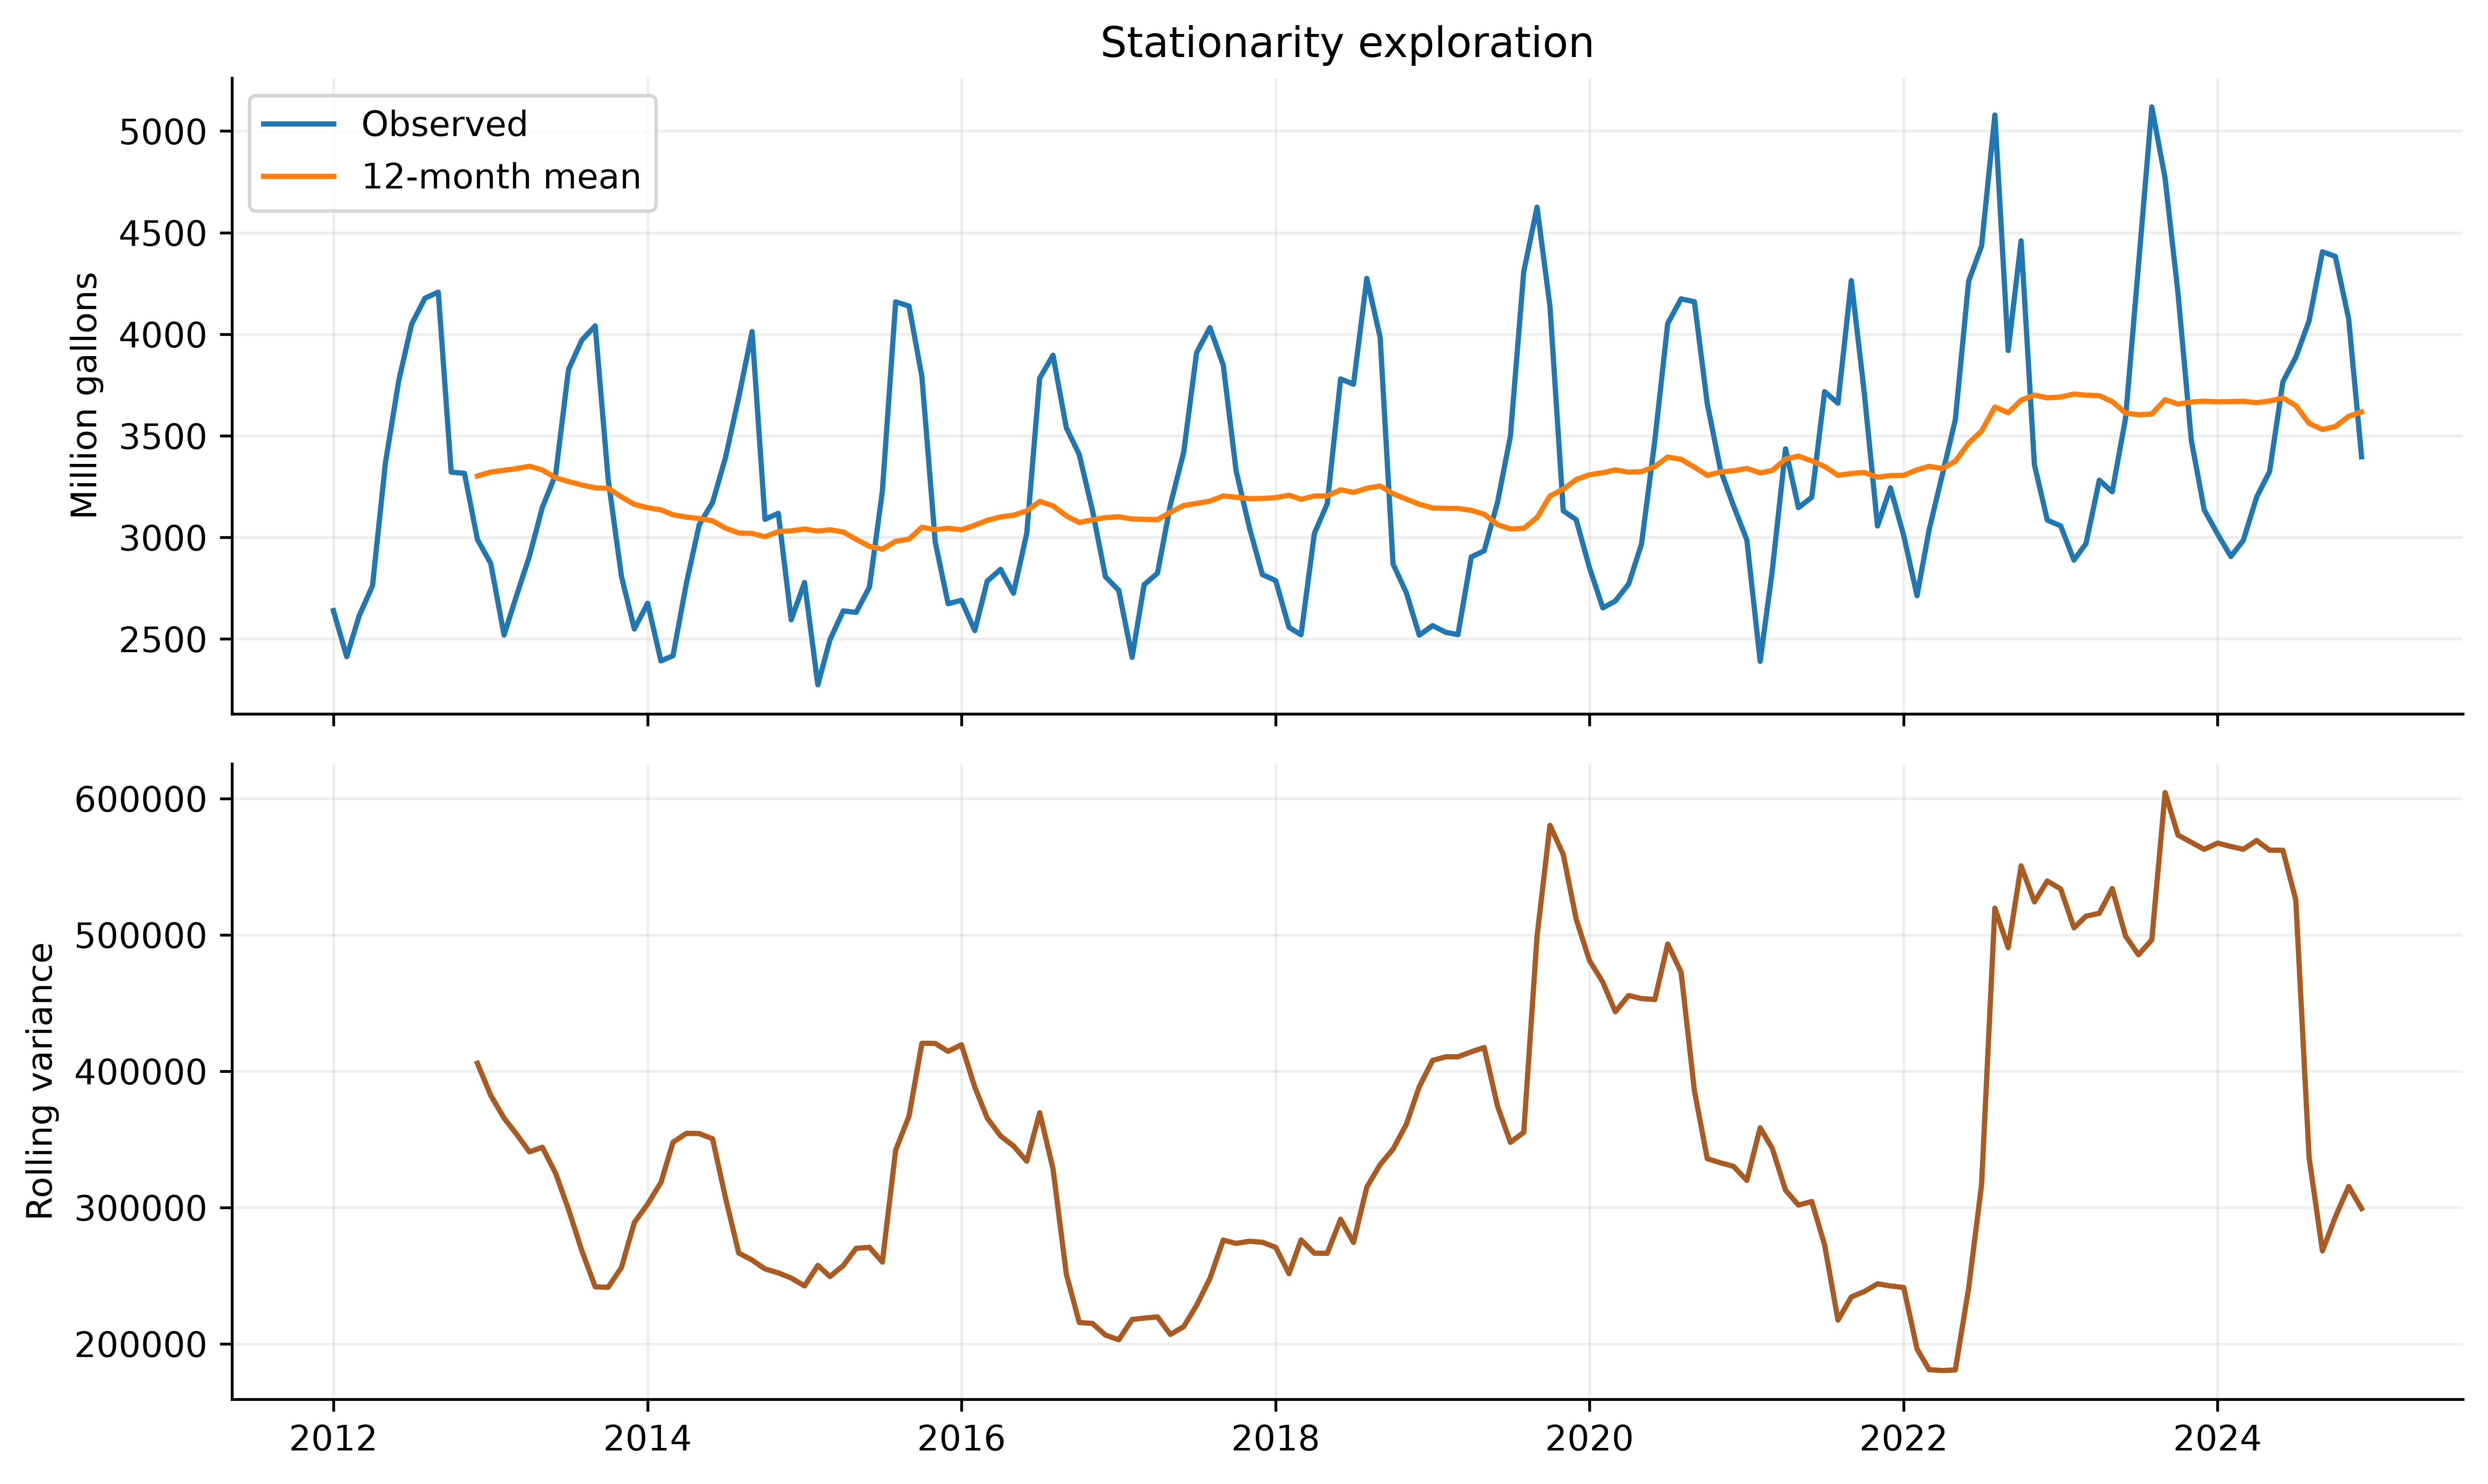

,statistic,pvalue,lags,nobs,critical_values
0,-0.157642,0.943386,11,120,"{'1%': -3.486055829282407, '5%': -2.8859430324..."
1,-9.693506,0.0,10,120,"{'1%': -3.486055829282407, '5%': -2.8859430324..."


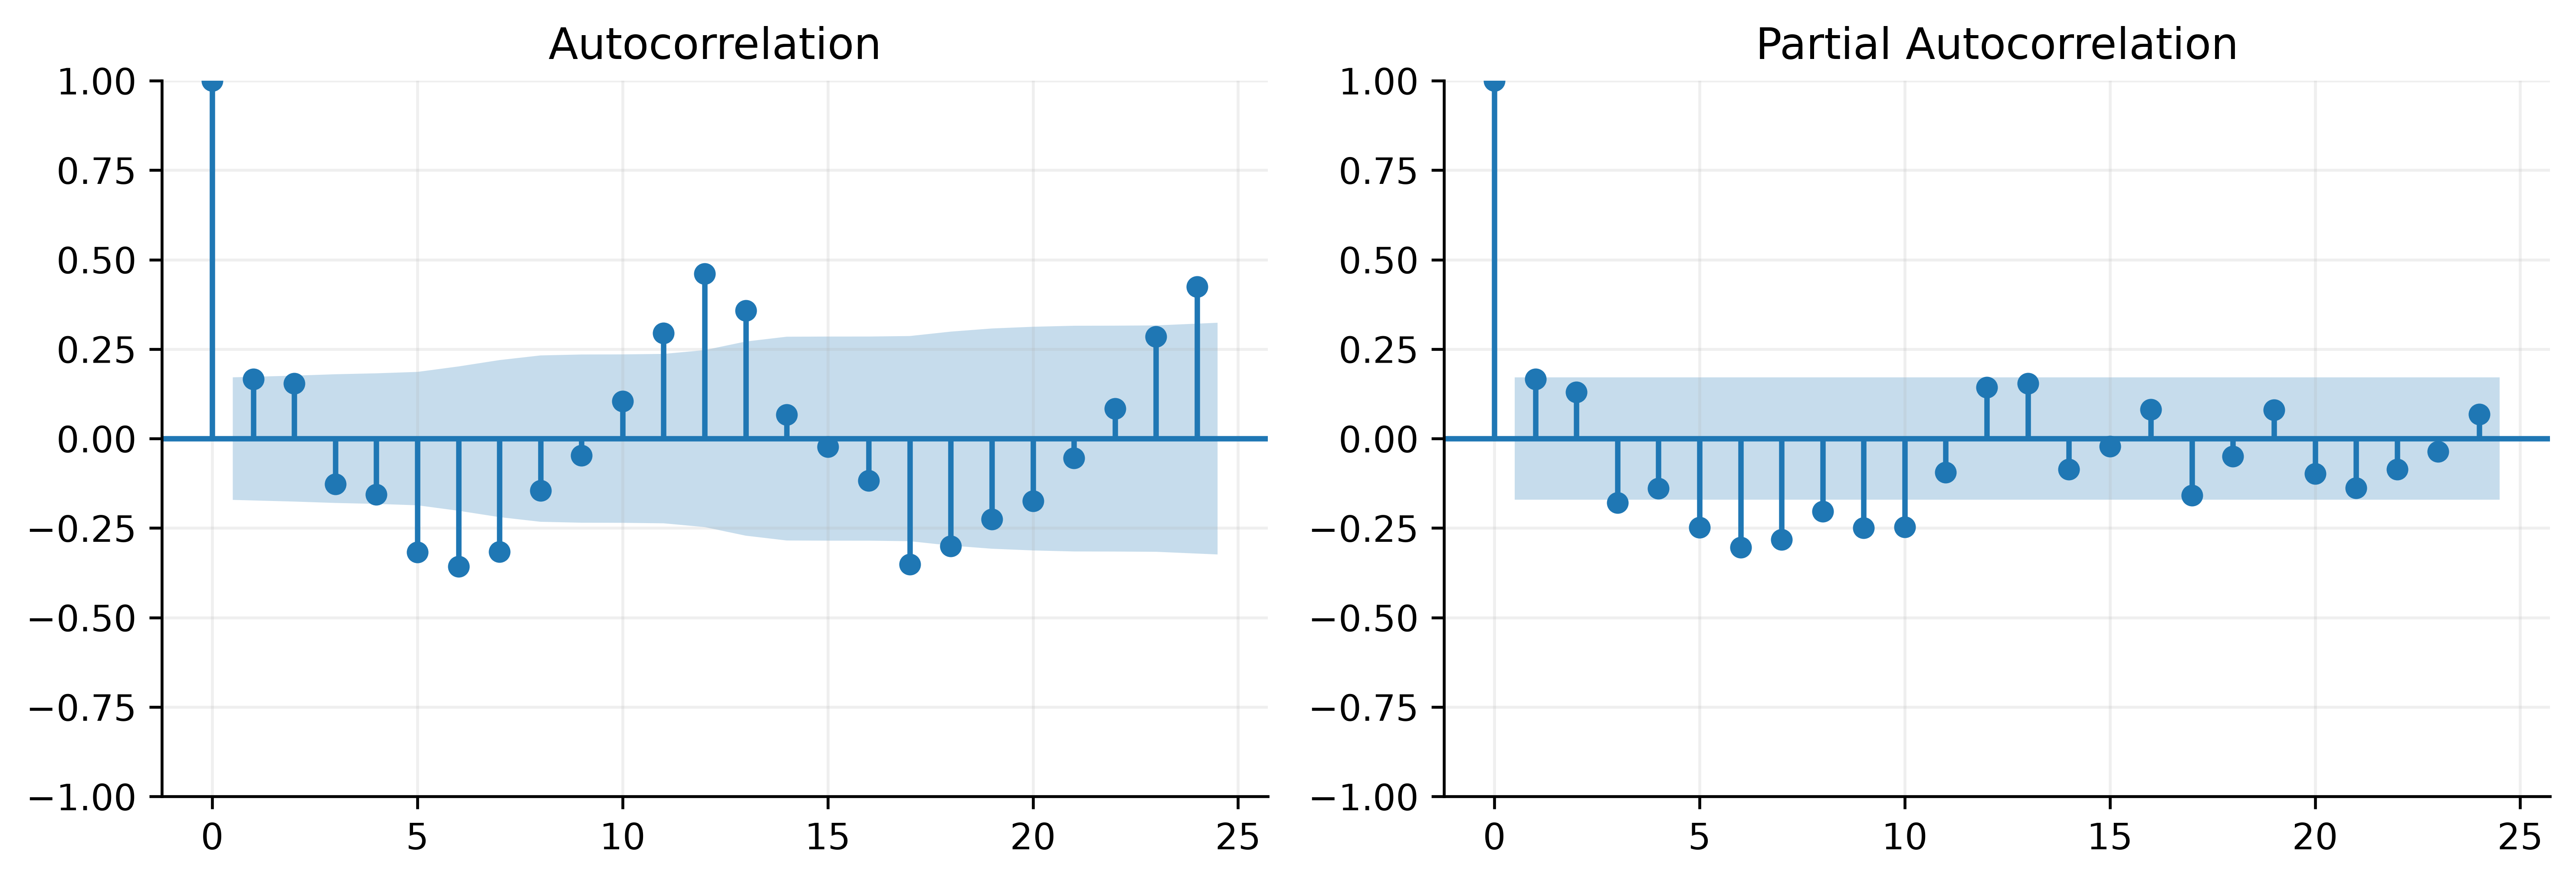

,p,d,q,AIC,converged,warnings
0,0,1,0,139.0945,True,NaN
1,0,1,1,138.3123,True,NaN
2,0,1,2,134.9047,True,NaN
3,1,1,0,137.4197,True,NaN
4,1,1,1,138.7801,True,NaN
5,1,1,2,125.0198,True,NaN
6,2,1,0,137.0201,True,NaN
7,2,1,1,136.4636,True,Non-stationary starting autoregressive paramet...
8,2,1,2,76.7076,True,NaN


In [4]:
display(Image(filename="results/figures/consumption.png", width=950))
display(Image(filename="results/figures/decomposition.png", width=950))
display(Image(filename="results/figures/stationarity.png", width=950))
display(pd.DataFrame(summary["adf_training"]).T)
display(Image(filename="results/figures/acf_pacf.png", width=950))
display(pd.read_csv("results/arima_grid.csv").round(4))

## 4 Forecasting models and evaluation
ARIMA, additive Holt–Winters, seasonal naive and weather/calendar regression use chronological splits. Future weather inputs use training-derived monthly climatology. The family with lowest validation RMSE is fixed before test evaluation. Errors use million US gallons per month; MAPE excludes zero actual values.

,model,validation_MAE,validation_RMSE,validation_MAPE,validation_MAPE_nonzero_n,test_MAE,test_RMSE,test_MAPE,test_MAPE_nonzero_n
0,Holt Winters,189.74,241.59,4.83,12,250.18,299.87,6.70,12
1,Seasonal naive,230.18,345.47,6.05,12,278.36,403.26,7.08,12
2,Weather calendar regression,280.50,382.14,6.89,12,191.49,250.14,5.01,12
3,ARIMA,431.85,519.91,12.05,12,215.69,245.98,6.13,12


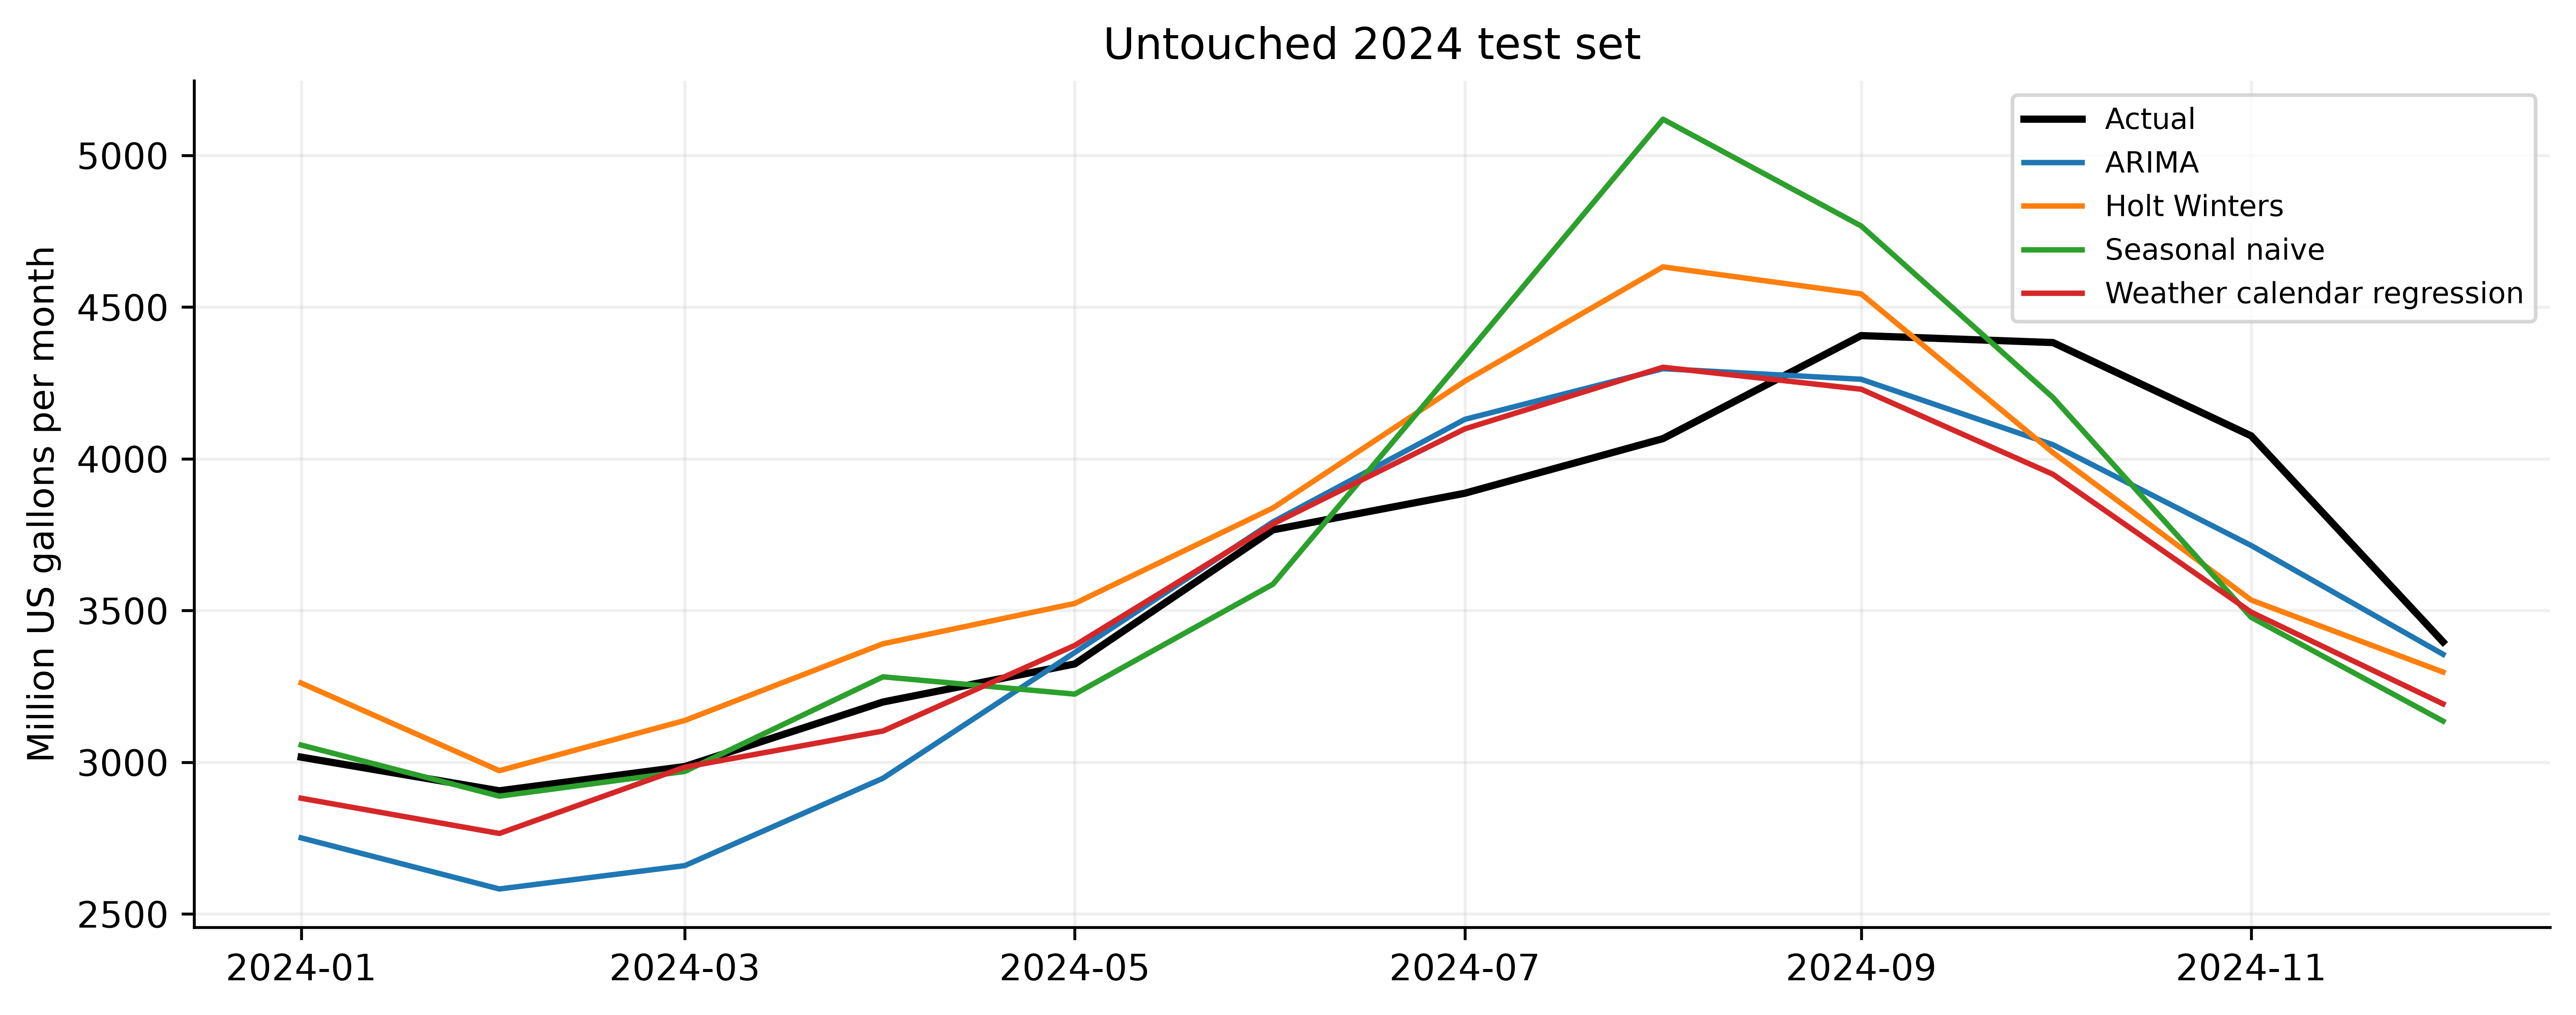

,date,selected_forecast_mg,Residential,Commercial,Large volume,Municipal
0,2025-01-01,3394.64,2143.91,896.15,294.37,60.20
1,2025-02-01,3118.88,1969.76,823.36,270.46,55.31
2,2025-03-01,3276.52,2069.32,864.97,284.13,58.11
3,2025-04-01,3524.81,2226.13,930.52,305.66,62.51
4,2025-05-01,3655.75,2308.82,965.08,317.01,64.83
5,2025-06-01,3979.07,2513.02,1050.44,345.05,70.57
6,2025-07-01,4372.52,2761.51,1154.30,379.17,77.55
7,2025-08-01,4733.57,2989.53,1249.62,410.48,83.95
8,2025-09-01,4676.48,2953.47,1234.55,405.53,82.94
9,2025-10-01,4191.42,2647.13,1106.50,363.46,74.33


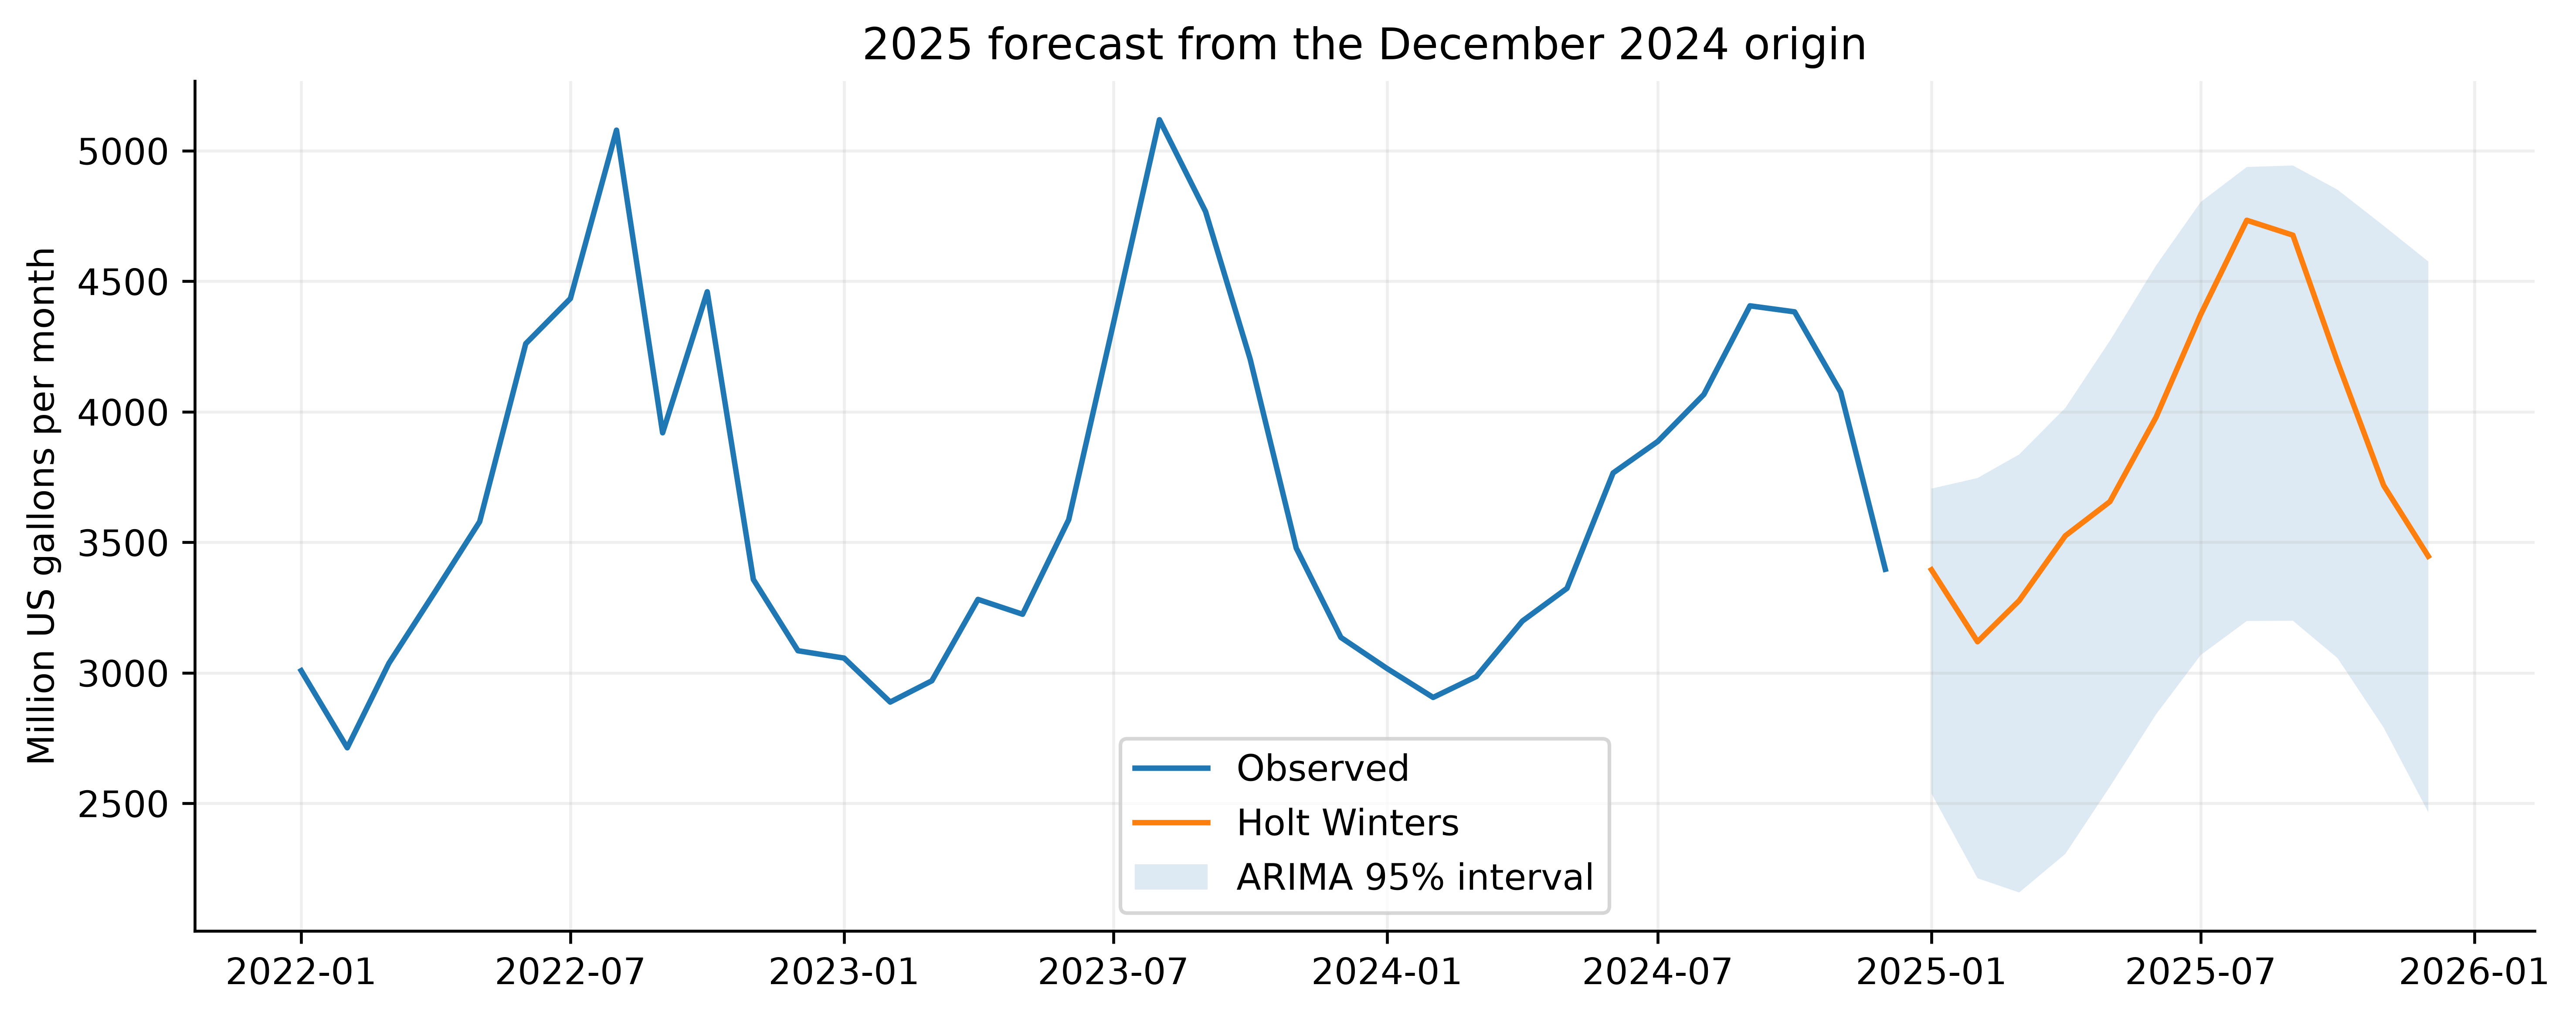

In [5]:
comparison = pd.read_csv("results/metrics.csv")
display(comparison.round(2))
display(Image(filename="results/figures/test_forecast.png", width=950))
future = pd.read_csv("results/future_forecast.csv")
display(future[["date", "selected_forecast_mg"] + SECTORS].round(2))
display(Image(filename="results/figures/future_forecast.png", width=950))

## 5 Abnormal consumption
Year-earlier residuals are scored against the median and MAD of prior residuals. Scores beyond ±3.5 are review alerts. Weather associations suggest possible explanations; no alert is a confirmed leak.

,date,actual_mg,robust_score,temperature_change_yoy_c,rainfall_change_yoy_mm,possible_explanation
45,2015-10-01,3790.44,3.75,0.66,198.2,Weather does not clearly explain alert directi...
93,2019-10-01,4137.80,4.84,0.71,-69.8,Drier than year-earlier month may support incr...
127,2022-08-01,5078.78,3.96,0.58,22.9,Weather does not clearly explain alert directi...
151,2024-08-01,4066.17,-5.31,-2.24,28.1,Cooler than year-earlier month may support red...


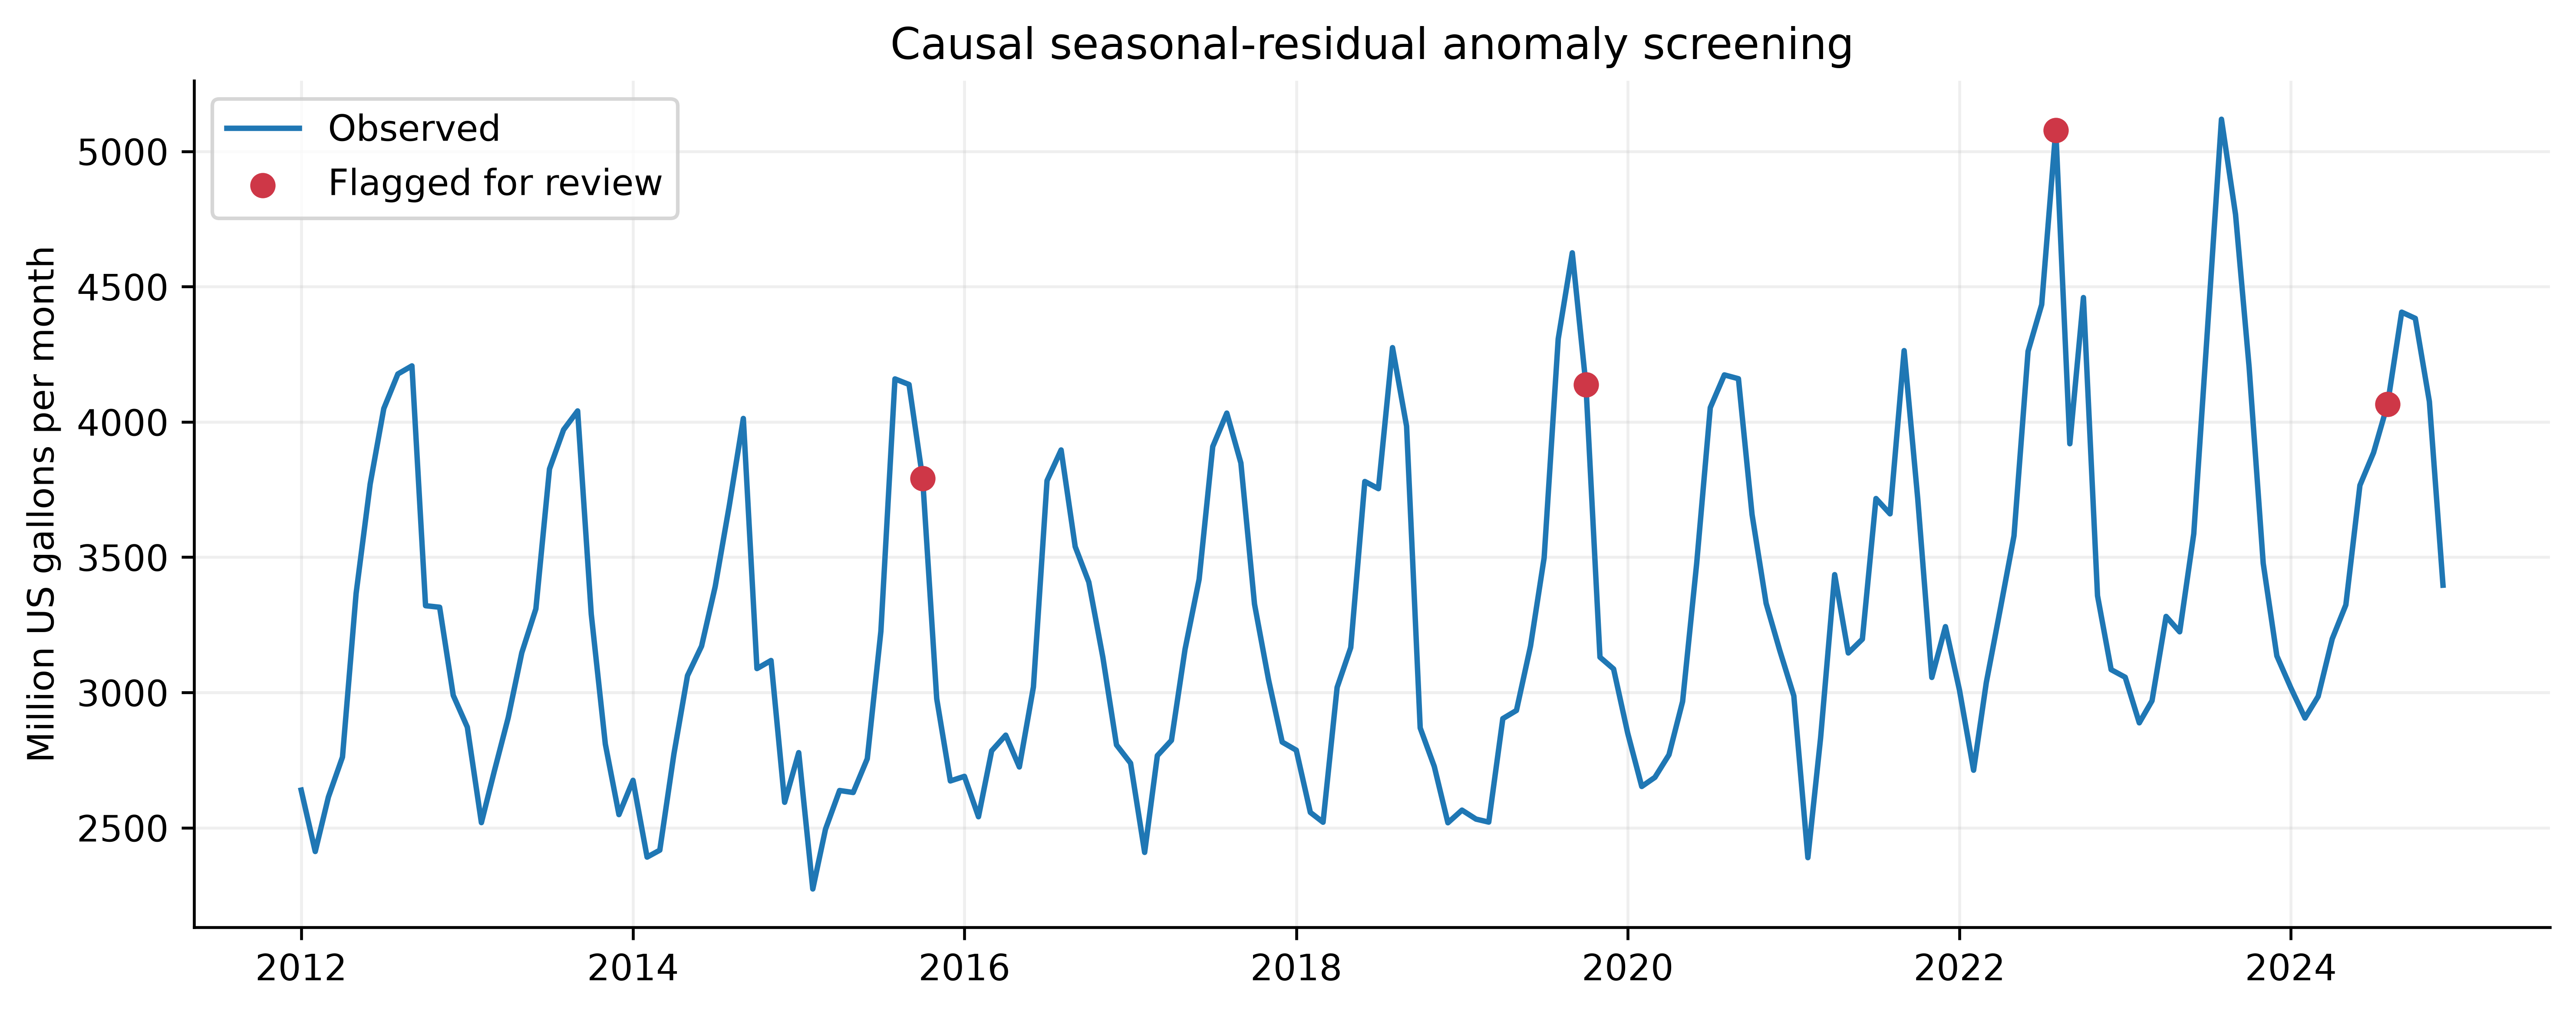

In [6]:
alerts = pd.read_csv("results/anomalies.csv")
flagged = alerts.loc[alerts["flag"]]
display(flagged[["date", "actual_mg", "robust_score", "temperature_change_yoy_c", "rainfall_change_yoy_mm", "possible_explanation"]].round(2))
display(Image(filename="results/figures/anomalies.png", width=950))

## 6 Resource allocation and decisions
Compare priority and proportional distribution at 75% supply, then demonstrate infeasibility at 35%. Minimum shares are 70%, 35%, 30% and 90% for residential, commercial, large volume and municipal. Priority weights are 4, 2, 1 and 5. Capacity is set equal to demand in this comparison; saved scenarios also explore different caps.

In [7]:
demand = future.loc[0, SECTORS].to_numpy(dtype=float)
for supply_fraction in [0.75, 0.35]:
    for policy in ["Priority", "Proportional"]:
        allocation, status = allocate(demand, float(demand.sum() * supply_fraction), policy)
        print(f"Supply {supply_fraction:.0%} | {policy}")
        print(json.dumps(status, indent=2))
        display(allocation.round(2))

Supply 75% | Priority
{
  "feasible": true,
  "action": "Maintain minimum service; conserve nonessential use and review sector shortfalls.",
  "unused_supply_mg": 0.0
}


,sector,demand_mg,capacity_mg,minimum_mg,allocated_mg,shortfall_mg,minimum_violation_mg
0,Residential,2143.91,2143.91,1500.74,2083.81,60.10,0.0
1,Commercial,896.15,896.15,313.65,313.65,582.50,0.0
2,Large volume,294.37,294.37,88.31,88.31,206.06,0.0
3,Municipal,60.20,60.20,54.18,60.20,0.00,0.0


Supply 75% | Proportional
{
  "feasible": true,
  "action": "Maintain minimum service; conserve nonessential use and review sector shortfalls.",
  "unused_supply_mg": 0.0
}


,sector,demand_mg,capacity_mg,minimum_mg,allocated_mg,shortfall_mg,minimum_violation_mg
0,Residential,2143.91,2143.91,1500.74,1764.27,379.65,0.0
1,Commercial,896.15,896.15,313.65,552.32,343.83,0.0
2,Large volume,294.37,294.37,88.31,172.74,121.63,0.0
3,Municipal,60.20,60.20,54.18,56.65,3.55,0.0


Supply 35% | Priority
{
  "feasible": false,
  "action": "EMERGENCY: minimum service infeasible. Escalate for tankers, backup supply or capacity restoration.",
  "unused_supply_mg": 0.0
}


,sector,demand_mg,capacity_mg,minimum_mg,allocated_mg,shortfall_mg,minimum_violation_mg
0,Residential,2143.91,2143.91,1500.74,911.17,1232.74,589.57
1,Commercial,896.15,896.15,313.65,190.43,705.72,123.22
2,Large volume,294.37,294.37,88.31,53.62,240.75,34.69
3,Municipal,60.20,60.20,54.18,32.90,27.31,21.29


Supply 35% | Proportional
{
  "feasible": false,
  "action": "EMERGENCY: minimum service infeasible. Escalate for tankers, backup supply or capacity restoration.",
  "unused_supply_mg": 0.0
}


,sector,demand_mg,capacity_mg,minimum_mg,allocated_mg,shortfall_mg,minimum_violation_mg
0,Residential,2143.91,2143.91,1500.74,911.17,1232.74,589.57
1,Commercial,896.15,896.15,313.65,190.43,705.72,123.22
2,Large volume,294.37,294.37,88.31,53.62,240.75,34.69
3,Municipal,60.20,60.20,54.18,32.90,27.31,21.29


## 7 Verify numerical results and integration
Tests exercise supply and capacity constraints, service floors, invalid inputs, duplicates, zero-safe errors, weather leakage and actual dashboard controls.

In [8]:
test_run = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"], capture_output=True, text=True)
print(test_run.stdout + test_run.stderr)
assert test_run.returncode == 0, "Tests failed; inspect output above."
from src.pipeline import metrics
observations = pd.read_csv("results/test_predictions.csv")
for _, row in comparison.iterrows():
    recalculated = metrics(observations.actual_mg, observations[row.model])
    for measure in ["MAE", "RMSE", "MAPE"]:
        assert np.isclose(recalculated[measure], row["test_" + measure])
print("All exported model errors independently recomputed and matched.")

test_dashboard_controls (test_dashboard.DashboardTests.test_dashboard_controls) ... 2026-10-16 20:57:39.861 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
ok
test_bad_input (test_system.SystemTests.test_bad_input) ... ok
test_capacity_can_make_floors_infeasible (test_system.SystemTests.test_capacity_can_make_floors_infeasible) ... ok
test_duplicates (test_system.SystemTests.test_duplicates) ... ok
test_emergency_is_explicit (test_system.SystemTests.test_emergency_is_explicit) ... ok
test_future_weather_cannot_leak_into_predictions (test_system.SystemTests.test_future_weather_cannot_leak_into_predictions) ... ok
test_invalid_record (test_system.SystemTests.test_invalid_record) ... ok
test_metrics_zero_handling (test_system.SystemTests.test_metrics_zero_handling) ... ok
test_supply_and_caps (test_system.SystemTests.test_supply_and_caps) ... ok
test_zero_demand (test_sys

## 8 Decision support and submission files
The six-tab dashboard is in `app.py`. Run it locally with `python -m streamlit run app.py`. The report, dashboard captures, executed notebook, raw data and generated CSV/PNG results are included in the repository. The notebook retains output cells when downloaded.

Sources: City of Austin residential dataset sxk7-7k6z and commercial dataset 5h9c-wmds (Public Domain per metadata); Open-Meteo historical ERA5 weather (CC BY 4.0). See `DATA_SOURCES.md` for attribution and `results/data_manifest.json` for source hashes.